# 16.20 - External Alignment Candidate Audit

This notebook audits three owner-supplied Roboflow YOLO exports for the spacing/crowding branch. The purpose is data qualification before any new training.

**Safety boundary:** only train and validation image/label contents were read. Test members were counted from ZIP directory metadata only; their bytes were not opened or extracted. Original ZIPs are immutable in `data/raw/alignment_external/`. No class remapping, clinical relabeling, Kaggle publication, or model training occurs here.

The full readable implementation is in `src/scripts/audit_external_alignment_candidates.py`; focused annotation sheets are rendered by `src/scripts/render_external_alignment_focus.py`. Run the script to recreate the artifacts referenced below.

## 1. Load the saved audit evidence

The audit script completed on the local machine. This notebook loads its saved JSON and per-image train/validation manifest so the evidence is reviewable without repeating the full image hashing pass.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image as NotebookImage

ROOT = Path.cwd()
REPORT_DIR = ROOT / "docs/reports/alignment/external_candidates_2026-11-18"
summary = json.loads((REPORT_DIR / "audit_summary.json").read_text(encoding="utf-8"))
manifest = pd.read_csv(REPORT_DIR / "train_valid_image_manifest.csv")

assert summary["policy"]["splits_read"] == ["train", "valid"]
assert summary["policy"]["test_unopened"] is True
assert set(manifest["split"].unique()) <= {"train", "valid"}
print(f"Manifest rows: {len(manifest):,}; test rows: {(manifest['split'] == 'test').sum()}")
display(manifest.groupby(["source", "split"]).size().rename("images").reset_index())

Manifest rows: 8,238; test rows: 0


,source,split,images
0,crowded_teeth_fipdz_v1,train,801
1,crowded_teeth_fipdz_v1,valid,147
2,dental_app_v8,train,117
3,dental_app_v8,valid,30
4,gigikita_discloration_v1,train,5559
5,gigikita_discloration_v1,valid,1584


## 2. Verify source archives and frozen split inventory

The split counts below come from each ZIP central directory. This does not read test images or labels.

In [2]:
archive_rows = []
for source in summary["sources"]:
    counts = source["archive_inventory"]["split_inventory"]
    for split in ("train", "valid", "test"):
        archive_rows.append({
            "source": source["source_id"], "split": split,
            "images_in_zip_metadata": counts[split]["image_files"],
            "labels_in_zip_metadata": counts[split]["label_txt_files"],
            "archive_sha256": source["archive_sha256"],
            "license_declared_in_yaml": source["license_from_data_yaml"],
        })
display(pd.DataFrame(archive_rows))

,source,split,images_in_zip_metadata,labels_in_zip_metadata,archive_sha256,license_declared_in_yaml
0,gigikita_discloration_v1,train,5559,5559,3cfa9499e0fe563b487a4db6a357668da75068ea3726e1...,CC BY 4.0
1,gigikita_discloration_v1,valid,1584,1584,3cfa9499e0fe563b487a4db6a357668da75068ea3726e1...,CC BY 4.0
2,gigikita_discloration_v1,test,790,790,3cfa9499e0fe563b487a4db6a357668da75068ea3726e1...,CC BY 4.0
3,dental_app_v8,train,117,117,d820a29cf7802ba8bc9c34b6270f3dcacb9625c3c945b7...,CC BY 4.0
4,dental_app_v8,valid,30,30,d820a29cf7802ba8bc9c34b6270f3dcacb9625c3c945b7...,CC BY 4.0
5,dental_app_v8,test,20,20,d820a29cf7802ba8bc9c34b6270f3dcacb9625c3c945b7...,CC BY 4.0
6,crowded_teeth_fipdz_v1,train,801,801,81506f74f33086e680cc37b45d9bd726be0de27f569f5a...,CC BY 4.0
7,crowded_teeth_fipdz_v1,valid,147,147,81506f74f33086e680cc37b45d9bd726be0de27f569f5a...,CC BY 4.0
8,crowded_teeth_fipdz_v1,test,116,116,81506f74f33086e680cc37b45d9bd726be0de27f569f5a...,CC BY 4.0


## 3. Compare class support without merging source vocabularies

Counts are source annotations. `Crowded`, `crowded`, `spacing`, and `diastema` are retained as distinct source labels until a reviewed annotation protocol says otherwise.

In [3]:
support_rows = []
for source in summary["sources"]:
    for split, stats in source["splits"].items():
        for label, boxes in stats["class_box_counts"].items():
            support_rows.append({
                "source": source["source_id"], "split": split,
                "source_label": label, "images_with_label": stats["class_image_counts"][label],
                "boxes": boxes, "empty_label_files": stats["empty_labels"],
                "unreadable_images": stats["decode_errors"],
            })
display(pd.DataFrame(support_rows))

,source,split,source_label,images_with_label,boxes,empty_label_files,unreadable_images
0,gigikita_discloration_v1,train,calculus,225,874,0,0
1,gigikita_discloration_v1,train,caries,862,2231,0,0
2,gigikita_discloration_v1,train,crowded,2145,4045,0,0
3,gigikita_discloration_v1,train,discoloration,326,737,0,0
4,gigikita_discloration_v1,train,gingivitis,749,3520,0,0
5,gigikita_discloration_v1,train,hypodontia,821,1624,0,0
6,gigikita_discloration_v1,train,openbite,436,456,0,0
7,gigikita_discloration_v1,valid,calculus,78,299,0,0
8,gigikita_discloration_v1,valid,caries,248,640,0,0
9,gigikita_discloration_v1,valid,crowded,665,1239,0,0


## 4. Check file pairing, geometry and candidate leakage

The audit checks exact SHA-256 duplicates and equal 64-bit dHash groups. SHA matches confirm byte identity; dHash matches only flag visually reviewable candidates. No dHash candidate was automatically removed.

In [4]:
pair_rows = []
for source in summary["sources"]:
    pair_rows.append({
        "source": source["source_id"],
        "invalid_label_or_geometry_rows": len(source["label_image_geometry_errors"]),
        "train_valid_exact_SHA_groups": len(source["cross_split_exact_duplicates"]),
        "train_valid_equal_dHash_groups": len(source["cross_split_identical_dhash_candidates"]),
        "images_missing_labels": sum(s["missing_labels"] for s in source["splits"].values()),
        "orphan_label_files": sum(s["orphan_label_files"] for s in source["splits"].values()),
        "decode_errors": sum(s["decode_errors"] for s in source["splits"].values()),
    })
display(pd.DataFrame(pair_rows))

by_hash = manifest.groupby("dhash64", dropna=True)
cross_source_groups = [g for _, g in by_hash if g["source"].nunique() > 1]
cross_source_train_valid_groups = [g for g in cross_source_groups if g["split"].nunique() > 1]
print(f"Cross-source equal-dHash groups: {len(cross_source_groups)}")
print(f"Cross-source equal-dHash groups crossing train/validation: {len(cross_source_train_valid_groups)}")
print(f"Exact byte-identical cross-source matches: {len(summary['cross_source_overlap']['candidate_cross_source_exact_duplicate_groups'])}")
print(f"Exact SHA overlap with current visible alignment train/validation: {summary['existing_project_overlap']['exact_overlap_count']}")

,source,invalid_label_or_geometry_rows,train_valid_exact_SHA_groups,train_valid_equal_dHash_groups,images_missing_labels,orphan_label_files,decode_errors
0,gigikita_discloration_v1,0,0,79,0,0,0
1,dental_app_v8,0,0,1,0,0,0
2,crowded_teeth_fipdz_v1,0,0,1,0,0,0


Cross-source equal-dHash groups: 625


Cross-source equal-dHash groups crossing train/validation: 203
Exact byte-identical cross-source matches: 0
Exact SHA overlap with current visible alignment train/validation: 0


## 5. Demonstrate YOLO box and segmentation-row handling

Some labels have five fields (`class, x_center, y_center, width, height`); a few have polygon vertices. The audit parser converts polygon vertices to min/max bounds for the overlay only and leaves original labels unchanged.

In [5]:
from PIL import Image
from src.scripts.audit_external_alignment_candidates import parse_yolo_label

polygon_example = None
for candidate in (ROOT / ".venv/work/alignment_external_audit").glob("*/train/labels/*.txt"):
    lines = candidate.read_text(encoding="utf-8", errors="replace").splitlines()
    row = next((line for line in lines if len(line.split()) > 5), None)
    if row:
        polygon_example = (candidate, row)
        break
assert polygon_example is not None
label_path, raw_row = polygon_example
image_path = label_path.parents[1] / "images" / f"{label_path.stem}.jpg"
with Image.open(image_path) as im:
    width, height = im.size
summary_source_ids = [s["source_id"] for s in summary["sources"]]
source_id = next(k for k in summary_source_ids if k in str(label_path))
classes = next(s["class_names_in_source_order"] for s in summary["sources"] if s["source_id"] == source_id)
objects, errors = parse_yolo_label(label_path, len(classes), width, height)
print("Source:", source_id)
print("Example source row fields:", len(raw_row.split()))
print("Parsed annotation formats:", sorted({obj["format"] for obj in objects}))
print("Parser errors:", errors)
assert not errors

Source: dental_app_v8
Example source row fields: 9
Parsed annotation formats: ['segmentation_polygon']
Parser errors: []


## 6. Inspect source annotations and repeated-scene candidates

Boxes are displayed exactly as source labels (except polygon-to-bounding-box rendering for audit). This visual review is for annotation and view consistency, not clinical diagnosis.

gigikita_discloration_v1_crowded_train_focus.jpg


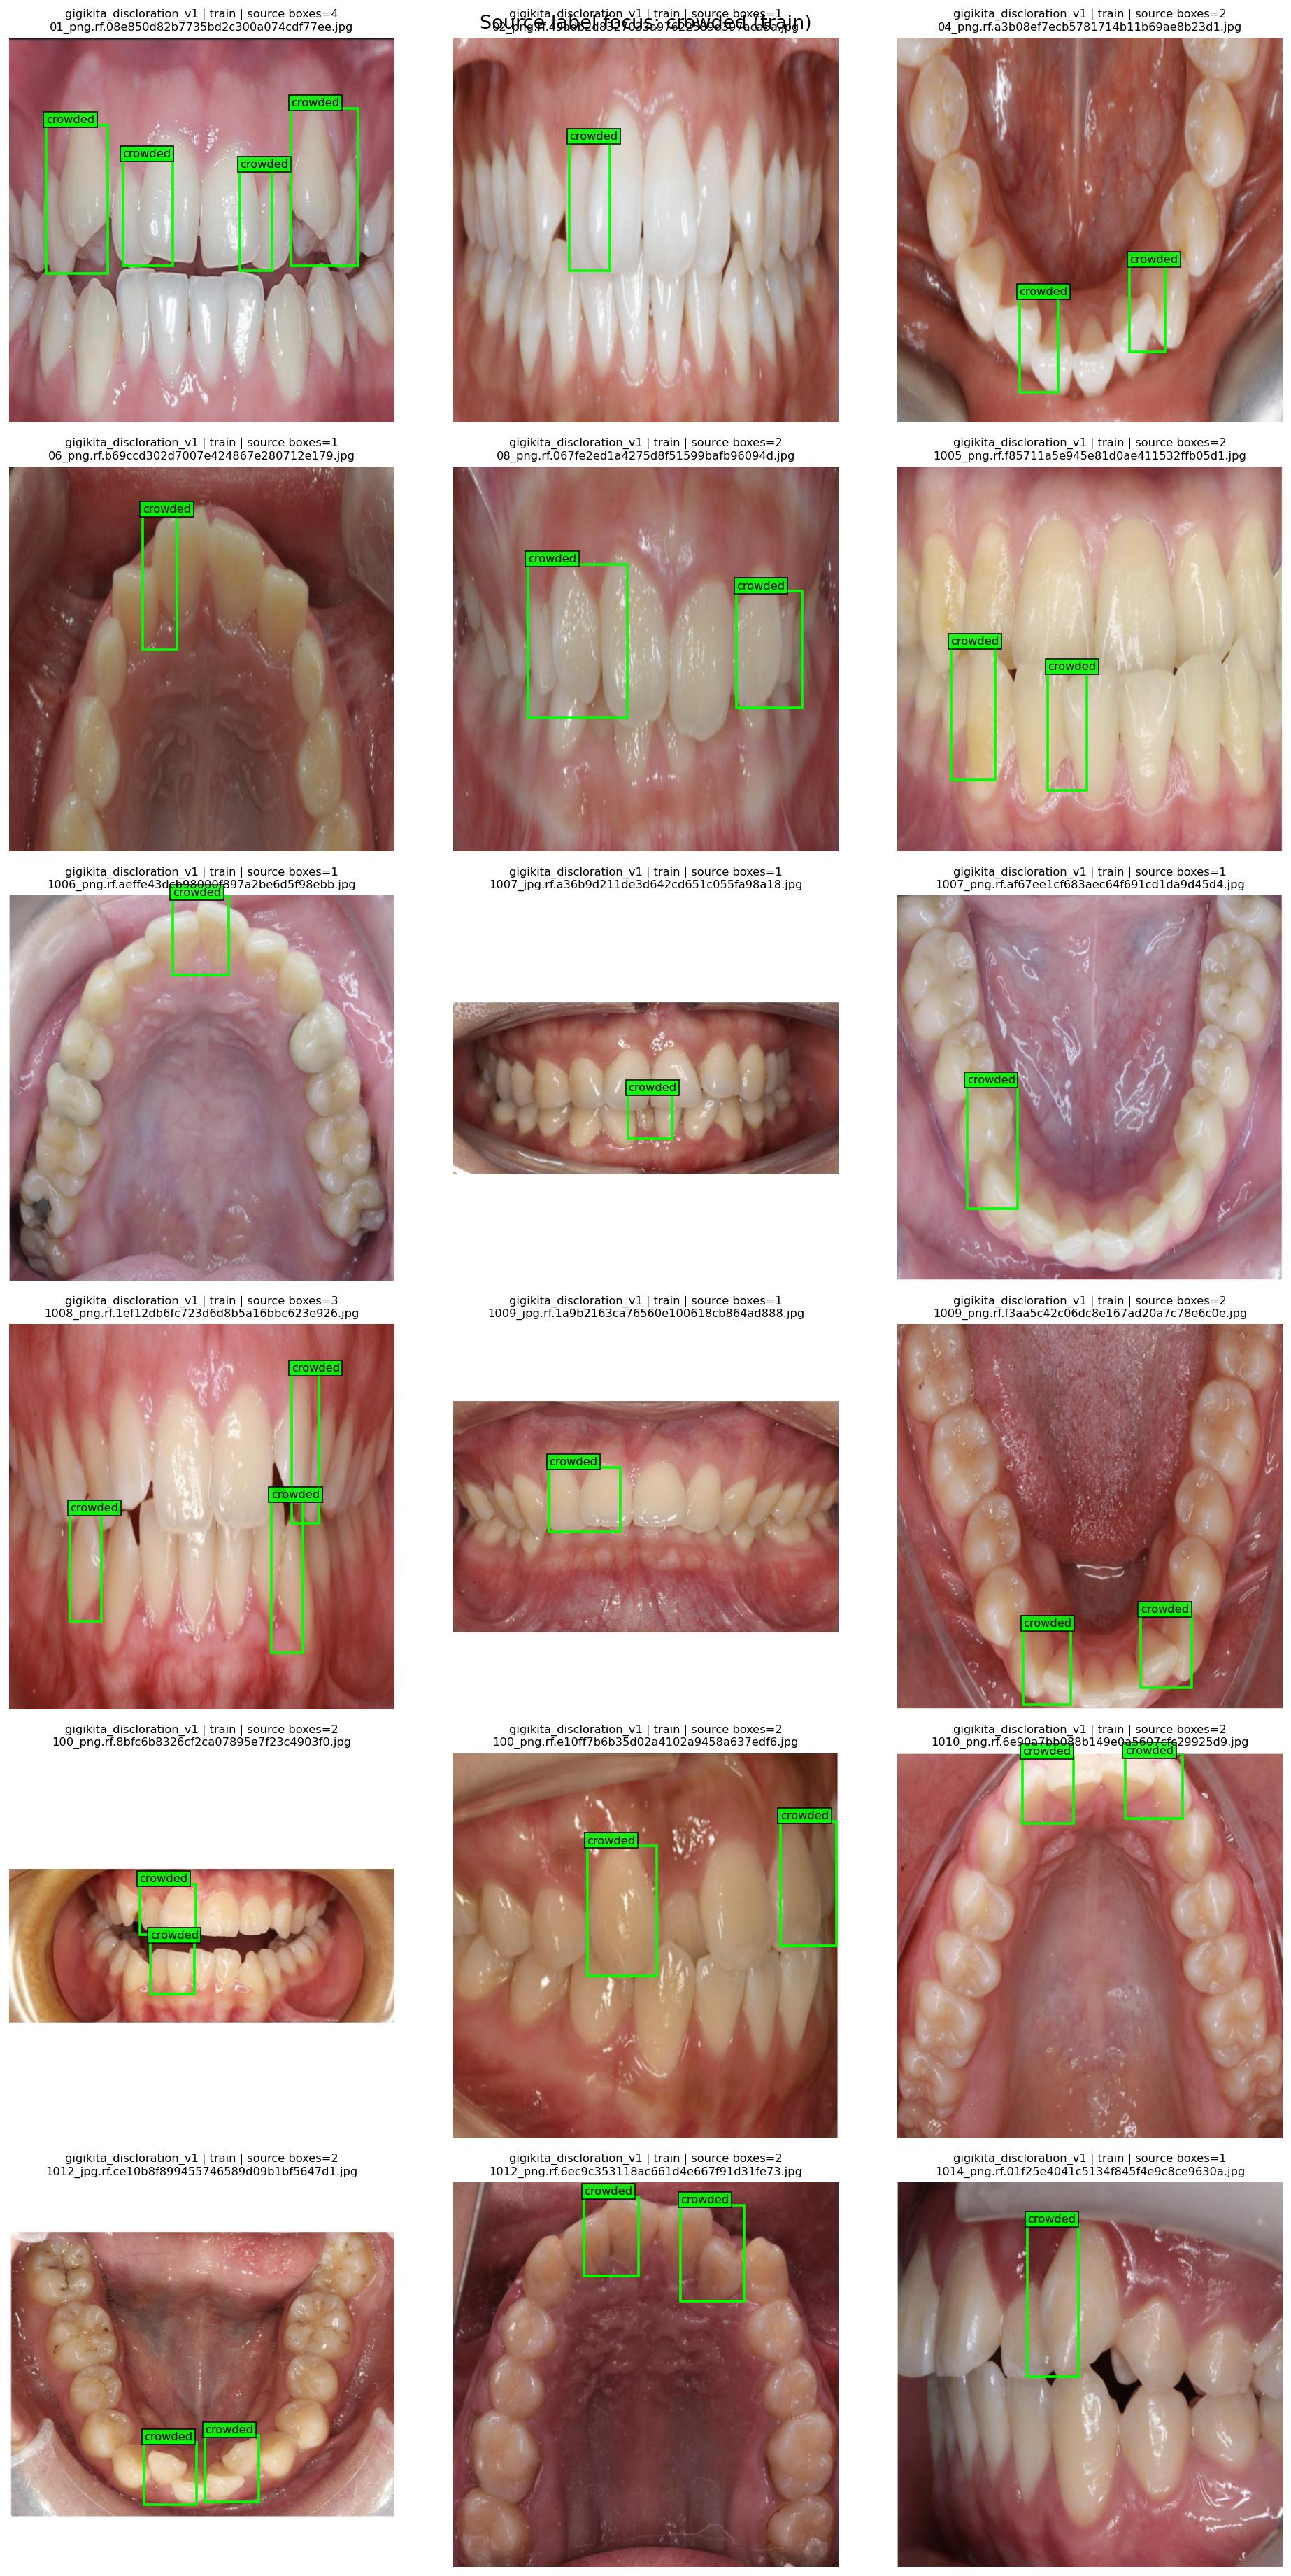

crowded_teeth_fipdz_v1_crowded_-_v1_2025-10-29_10-35am_train_focus.jpg


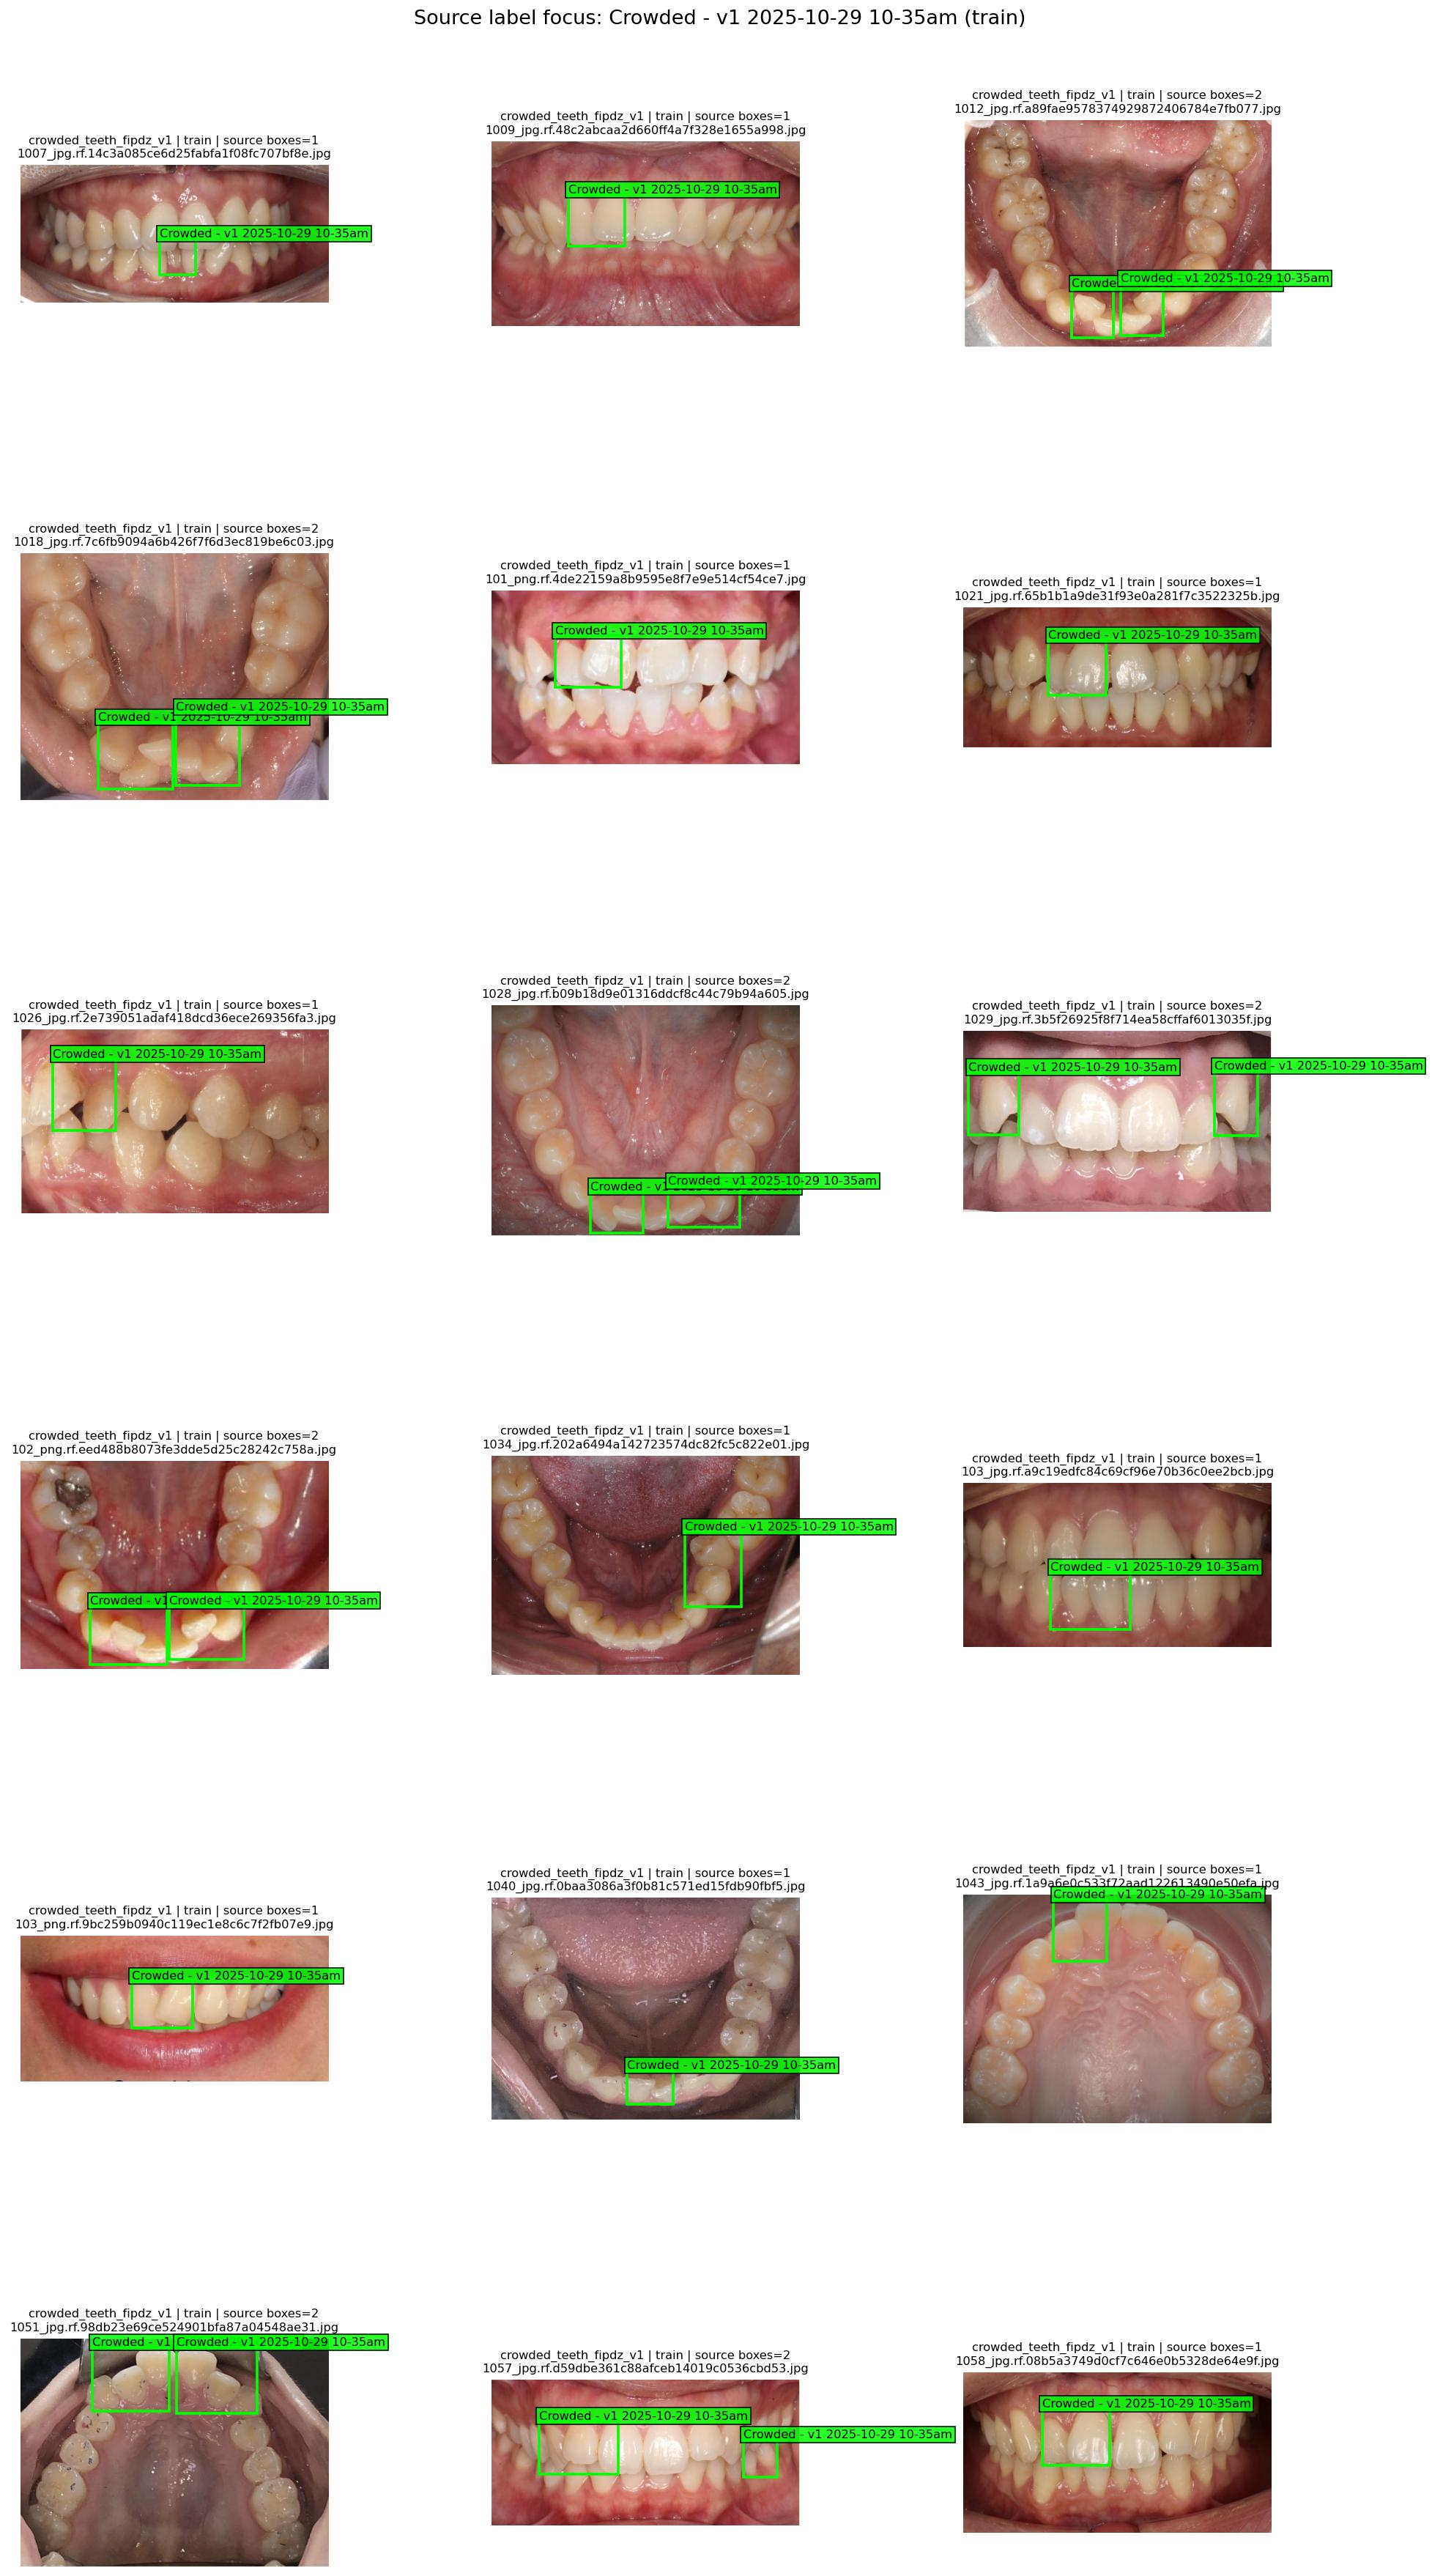

dental_app_v8_diastema_train_focus.jpg


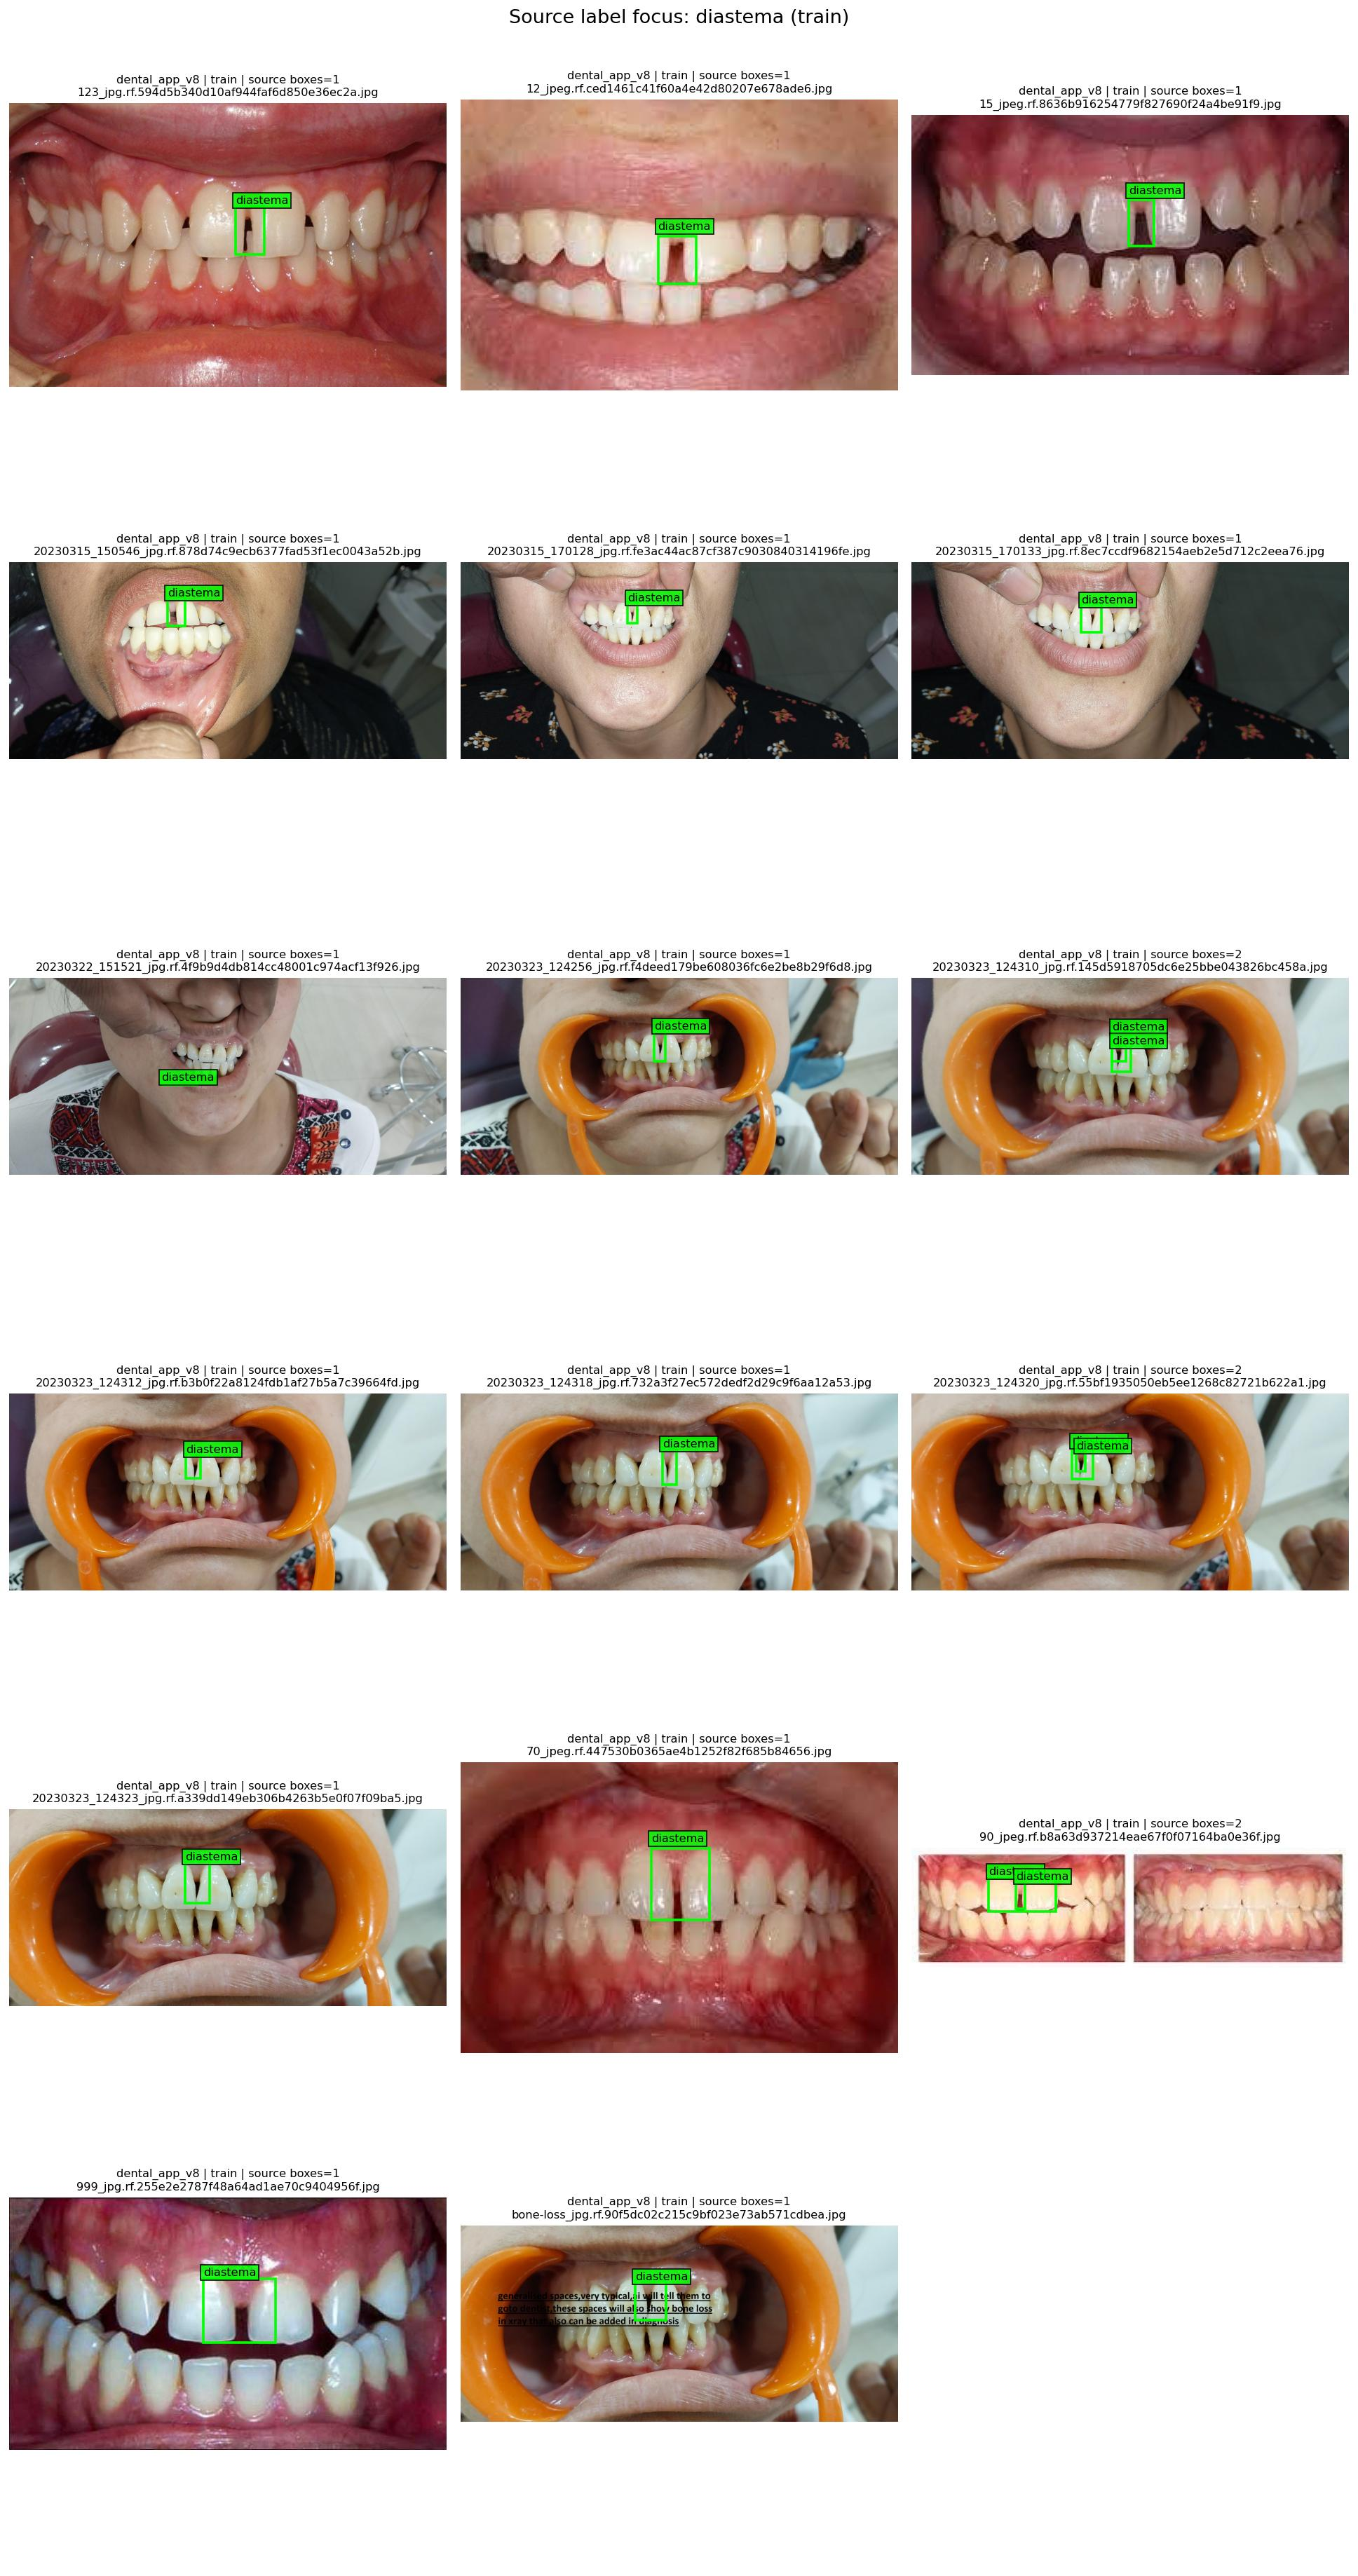

dental_app_v8_spacing_valid_focus.jpg


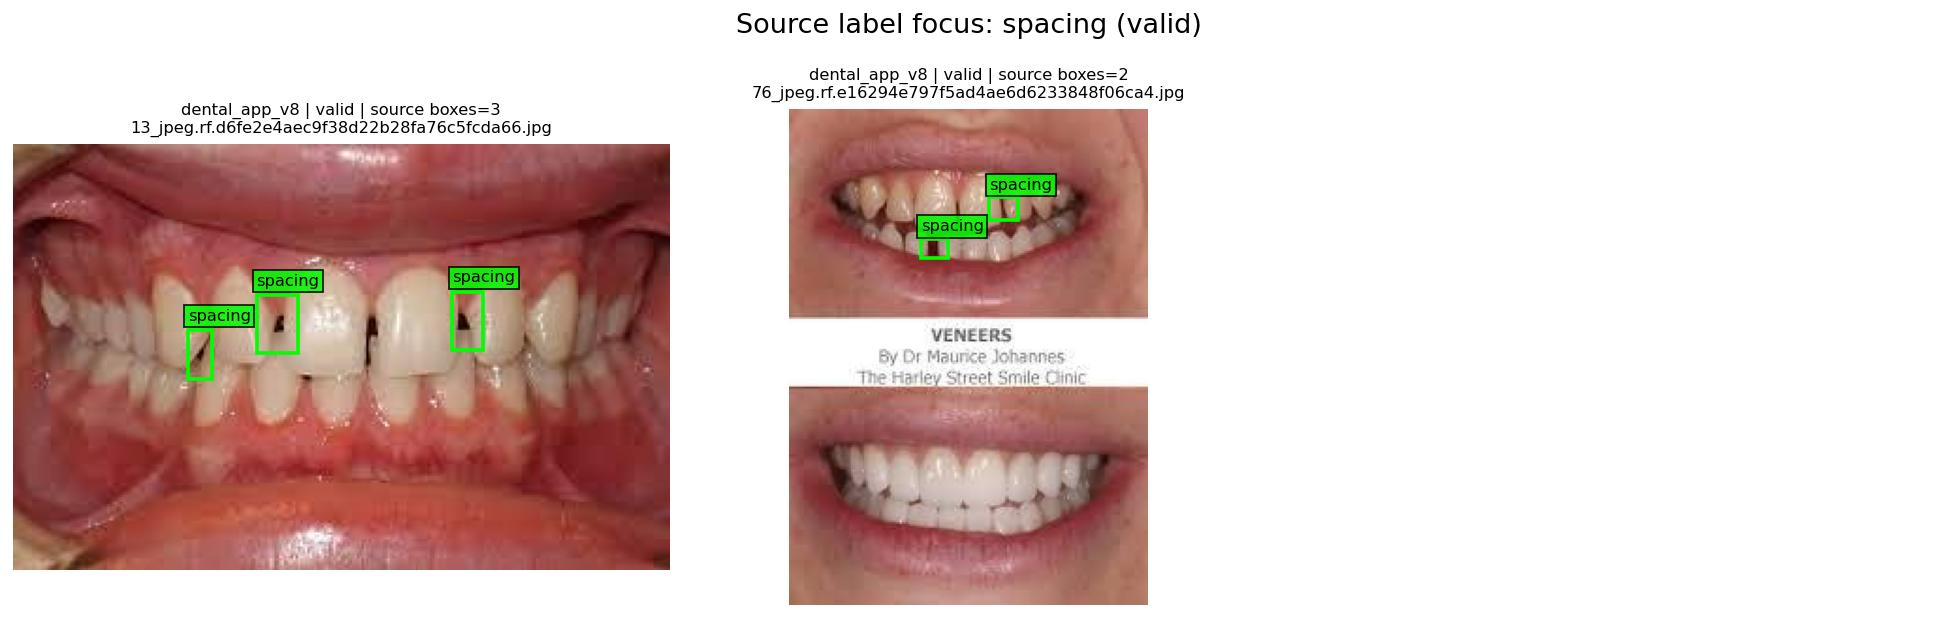

cross_source_dhash_review.jpg


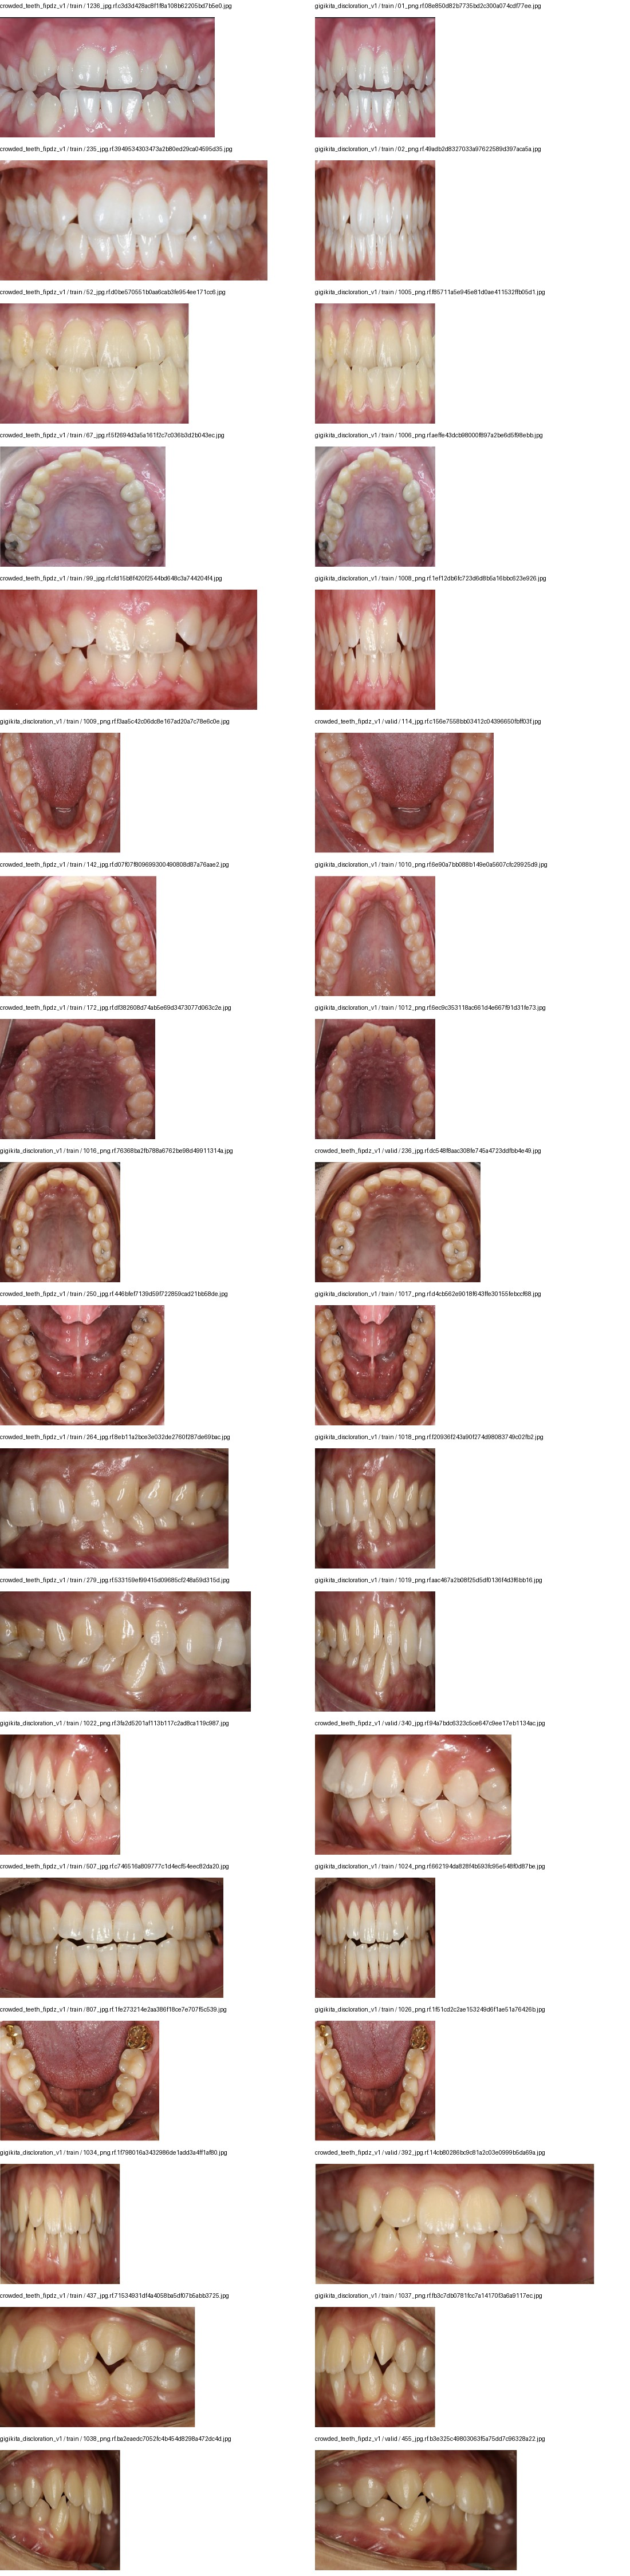

cross_source_split_conflict_review.jpg


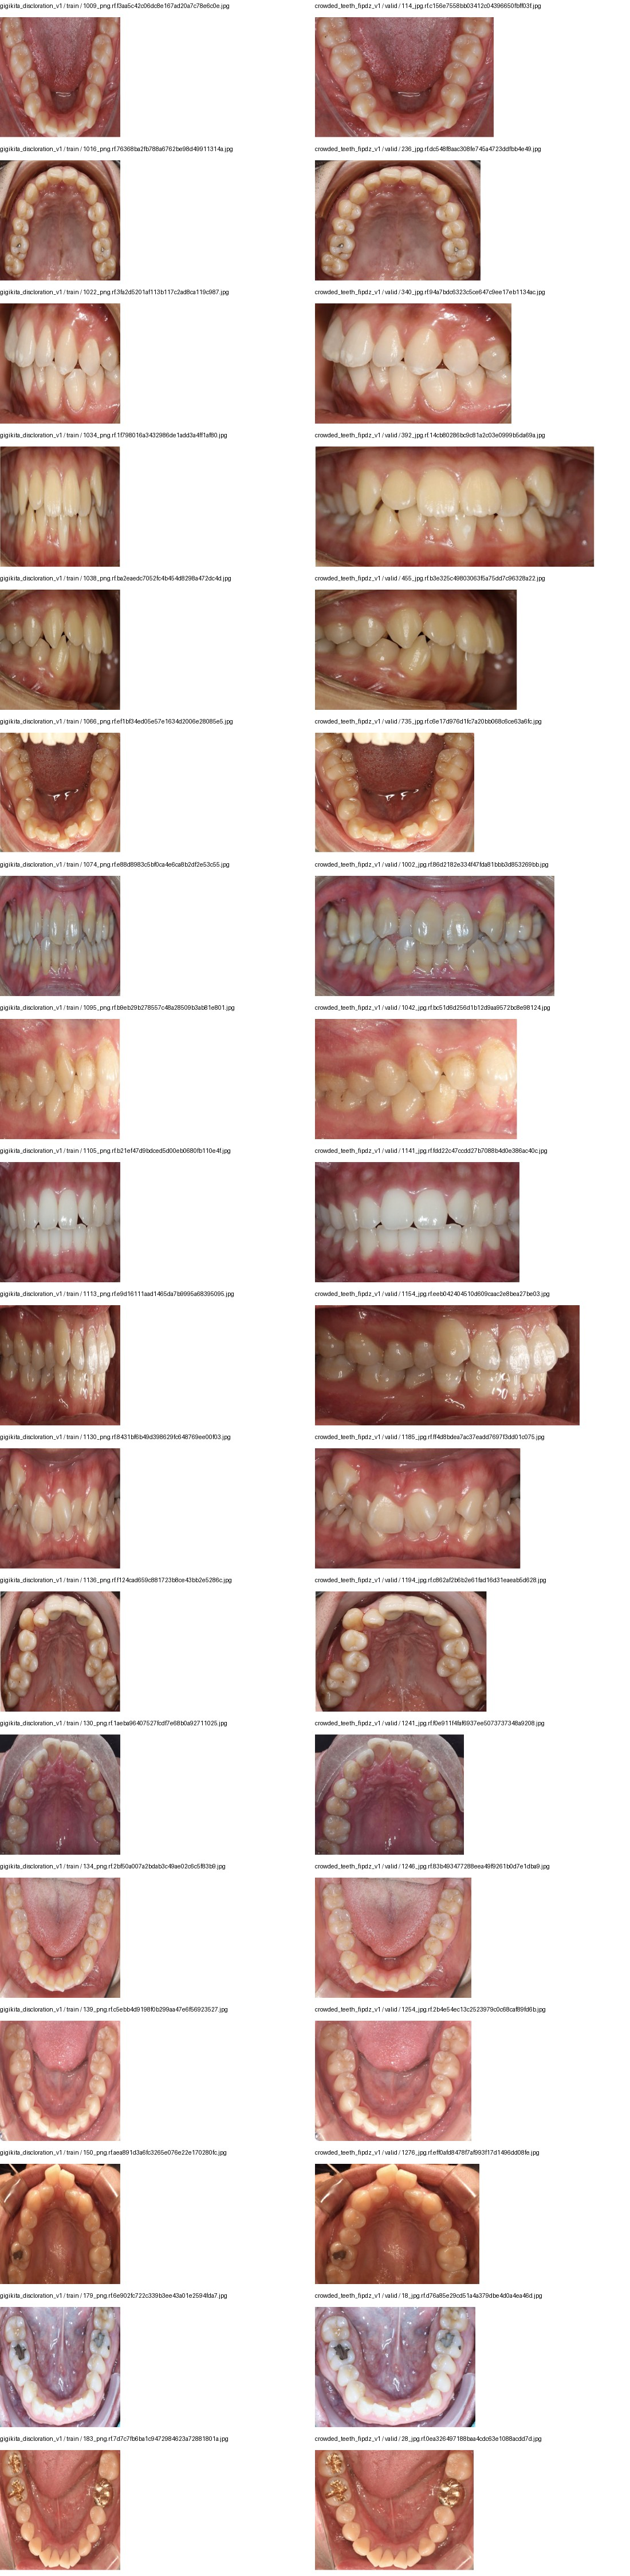

within_source_dhash_review.jpg




In [6]:
sheets = [
    "gigikita_discloration_v1_crowded_train_focus.jpg",
    "crowded_teeth_fipdz_v1_crowded_-_v1_2025-10-29_10-35am_train_focus.jpg",
    "dental_app_v8_diastema_train_focus.jpg",
    "dental_app_v8_spacing_valid_focus.jpg",
    "cross_source_dhash_review.jpg",
    "cross_source_split_conflict_review.jpg",
    "within_source_dhash_review.jpg",
]
for filename in sheets:
    path = REPORT_DIR / filename
    print(filename)
    display(NotebookImage(filename=str(path), width=900))

## 7. Qualification decision

- Do not merge the three archives or report scores from their original validation splits as independent evidence. Cross-source dHash groups and the reviewed contact sheet show repeated/near-repeated scenes between GigiKita and FIPDZ, including split conflicts.
- For a future single-source crowding pilot, FIPDZ is a bounded candidate; GigiKita has more labeled boxes but needs duplicate-aware regrouping and a review of the broad per-tooth box convention.
- Dental App remains a separate small candidate. The validation support is 2 diastema boxes and 5 spacing boxes, too small for stable model comparison; its labels are not equivalent by default.
- No patient identifiers are supplied, so even a duplicate-aware split cannot establish patient-level independence.
- This notebook creates no model score, no Kaggle artifact and no clinical performance claim. The next gate is a duplicate-aware, source-specific manifest and an explicit target box protocol.

## Implementation appendix

Recreate the audit and images from the immutable archives with:

```powershell
.\.venv\Scripts\python.exe src\scripts\audit_external_alignment_candidates.py --summary
.\.venv\Scripts\python.exe src\scripts\render_external_alignment_focus.py
```

The audit script validates ZIP paths, extracts only `train/` and `valid/`, checks normalized box/polygon coordinates without clipping, hashes images, and writes the summary plus manifest. Review `docs/reports/alignment/EXTERNAL_ALIGNMENT_CANDIDATE_AUDIT_2026-11-18.md` for the recorded findings.